In [1]:
import pandas as pd
import anndata as ad
import numpy as np

In [ ]:
tx_df = pd.read_csv('/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep3_tx_file.csv')
samples = tx_df.groupby('fov').sample(frac=0.001)

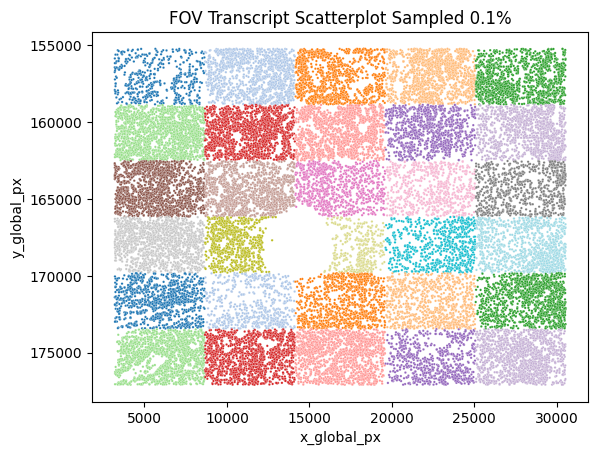

In [3]:
import seaborn as sns
ax=sns.scatterplot(data=samples, x='x_global_px', y='y_global_px', hue='fov',palette='tab20',s=3)
ax.set_title("FOV Transcript Scatterplot Sampled 0.1%")
ax.legend_.remove()
ax.invert_yaxis()

In [4]:
marker_genes = ['KRT8','KRT19','KRT18','TACSTD2','CEACAM6',
                'LUM','DCN','COL1A2','COL3A1','COL6A3',
                'C1QA','MRC1','C1QB','CD163','OLR1']

In [2]:
sc_data = ad.read_h5ad("/compute/oven-0-13/jwinchel/processed_adata/SC_NSCLC_TRAIN_FIRSTREP_10reps_withprobs.h5ad")
st_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/processed_adata/NSCLC_ST_withprobs.h5ad')
# sc_data_val = ad.read_h5ad('/compute/oven-0-13/jwinchel/processed_adata/SC_NSCLC_VAL_10reps_withprobs.h5ad')
# sc_data = ad.read_h5ad
# sc_data = sc_data[sc_data.obs.index.str.endswith("_0")]
sc_data.obs['cell_type'] = sc_data.obs['cell_type'].replace({"T CD4 naive": "T CD4+", 
                                                                "T CD4 memory": "T CD4+", 
                                                                "T CD8 naive": "T CD8+", 
                                                                "T CD8 memory": "T CD8+",
                                                                "pDC":"DC",
                                                                "mDC":"DC"})
l5r1_metadata = pd.read_csv('/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_metadata_file.csv')

st_data = st_data[st_data.obs['Run_Tissue_name']=='Lung5_Rep1']
st_data.obs = st_data.obs.merge(l5r1_metadata[['fov','cell_ID','CenterX_local_px',
       'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px']],on=['fov','cell_ID'])

In [6]:
sc_data

AnnData object with n_obs × n_vars = 403590 × 957
    obs: 'species', 'filename', 'sample', 'GSM_ID', 'cell_ID', 'Patient', 'Tissue', 'Barcoding emulsion', 'Library', 'Total counts', 'Percent counts from mitochondrial genes', 'Most likely LM22 cell type', 'Major cell type', 'Minor subset', 'used_in_NSCLC_all_cells', 'used_in_NSCLC_and_blood_immune', 'used_in_NSCLC_immune', 'used_in_NSCLC_non_immune', 'used_in_blood', 'Barcode', 'batch', 'cell_type', 'tissue', 'ADM_ID_0', 'ADM_ID_1', 'ADM_ID_2', 'split'
    uns: 'cell_type_dict'
    obsm: 'X_pca_harmony'
    layers: 'admixed', 'is_transcript_added'

In [7]:
sc_data.uns

{'cell_type_dict': {'B-cell': -1,
  'DC': -2,
  'NK': -3,
  'T CD4+': -4,
  'T CD8+': -5,
  'Treg': -6,
  'endothelial': -7,
  'epithelial': -8,
  'fibroblast': -9,
  'macrophage': -10,
  'mast': -11,
  'monocyte': -12,
  'neutrophil': -13,
  'plasmablast': -14,
  'tumor': -15}}

In [ ]:
keep_cts = (sc_data.obs['cell_type'].value_counts()>1000).index.tolist()

In [ ]:
sc_data[sc_data.obs['cell_type'].isin(keep_cts)]

In [30]:
st_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/cosmx_nsclc_Lung5-Rep1_adata_annotated_med_with_admix_probs.h5ad')
# sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/scRNA-seq/adata/GSE127465_tumor_integrated.h5ad')
# sc_data = ad.concat([ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_val_med_with_admix_probs.h5ad'),
#                     ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_train_med_with_admix_probs.h5ad')],
#                     join='outer')
sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_train_med_with_admix_probs.h5ad')

In [33]:
sc_data.layers['admix_probs']

<318955x924 sparse matrix of type '<class 'numpy.float32'>'
	with 26589855 stored elements in Compressed Sparse Row format>

In [34]:
sc_data = sc_data[sc_data.obs['harmony_spatial_tissue']=='Lung5_Rep1']

In [9]:
st_data.obs['fov'] = 1

In [35]:
import numpy as np
import pandas as pd

from admix_scores import estimate_cell_adjacency, estimate_cell_type_adjacency

# ----------------------------
# 1) Build a cell-level dataframe from st_data
# ----------------------------
def build_cell_df_from_st_data(
    st_data,
    *,
    cell_type_col="cell_type",
    fov_col="fov",
    # Choose ONE of these coordinate sources:
    x_col=None,  # e.g. "CenterX_global_px" or "x_global_px"
    y_col=None,  # e.g. "CenterY_global_px" or "y_global_px"
    obsm_key="spatial",  # fallback if x_col/y_col not present
    # optional unit conversion
    px_to_um=None,       # e.g. 0.18 if 180nm per pixel
):
    obs = st_data.obs.copy()

    if cell_type_col not in obs.columns:
        raise KeyError(f"{cell_type_col!r} not found in st_data.obs")
    if fov_col not in obs.columns:
        raise KeyError(f"{fov_col!r} not found in st_data.obs")

    # cell ids (use obs_names so they match other outputs)
    obs["cell"] = st_data.obs_names.astype(str)

    # coordinates
    if x_col is not None and y_col is not None:
        if x_col not in obs.columns or y_col not in obs.columns:
            raise KeyError(f"x_col/y_col not found in obs: {x_col}, {y_col}")
        obs["x"] = obs[x_col].astype(float)
        obs["y"] = obs[y_col].astype(float)
    else:
        if obsm_key not in st_data.obsm:
            raise KeyError(
                f"Neither x_col/y_col provided nor st_data.obsm[{obsm_key!r}] found."
            )
        xy = np.asarray(st_data.obsm[obsm_key])
        if xy.shape[1] != 2:
            raise ValueError(f"st_data.obsm[{obsm_key!r}] must be (n,2), got {xy.shape}")
        obs["x"] = xy[:, 0].astype(float)
        obs["y"] = xy[:, 1].astype(float)

    # optional unit conversion
    if px_to_um is not None:
        obs["x"] *= float(px_to_um)
        obs["y"] *= float(px_to_um)

    # keep only what adjacency needs + fov for grouping
    cell_df = obs[["x", "y", cell_type_col, "cell", fov_col]].rename(
        columns={cell_type_col: "cell_type", fov_col: "fov"}
    )

    # drop missing
    cell_df = cell_df.dropna(subset=["x", "y", "cell", "cell_type", "fov"]).reset_index(drop=True)
    return cell_df


# Example: choose coordinate source
# If you have centroid columns in obs:
# cell_df = build_cell_df_from_st_data(st_data, x_col="CenterX_global_px", y_col="CenterY_global_px", px_to_um=0.18)

# If you have obsm["spatial"]:
cell_df = build_cell_df_from_st_data(
    st_data,
    cell_type_col="cell_type",
    fov_col="fov",
    x_col='CenterX_global_px',
    y_col='CenterY_global_px',
    # x_col='sampled_st_x',
    # y_col='sampled_st_y',
    obsm_key="spatial",
    px_to_um=None,   # set to 0.18 if those coords are pixels and you want microns
)

# optional: collapse labels the same way you’ve been doing
cell_df["cell_type"] = cell_df["cell_type"].replace({
    "T CD4 naive": "T CD4+",
    "T CD4 memory": "T CD4+",
    "T CD8 naive": "T CD8+",
    "T CD8 memory": "T CD8+",
    "pDC": "DC",
    "mDC": "DC",
}).astype(str)
cell_df.loc[cell_df["cell_type"].astype(str).str.startswith("tumor"), "cell_type"] = "tumor"


# ----------------------------
# 2) Compute cell adjacency per FOV, concatenate, then compute type adjacency once
# ----------------------------
edge_kwargs = dict(
    random_shift=1e-3,
    edge_max_mad=4.0,
    n_jobs=1,
)

all_edges = []
for fov, g in cell_df.groupby("fov", sort=True):
    g = g[["x", "y", "cell_type", "cell"]].copy()
    if g["cell"].nunique() < 4:
        continue

    adj = estimate_cell_adjacency(g, **edge_kwargs)
    if adj is None or len(adj) == 0:
        continue

    all_edges.append(adj)

if len(all_edges) == 0:
    raise RuntimeError("No adjacency edges computed (check coords/cell counts per FOV).")

cell_adj_df = pd.concat(all_edges, axis=0, ignore_index=True)

# One global K from all cell-cell edges across all FOVs
cell_type_adj = estimate_cell_type_adjacency(cell_adj_df)

# Ensure square + consistent ordering
all_types = sorted(cell_df["cell_type"].dropna().unique().tolist())
cell_type_adj = (
    pd.DataFrame(cell_type_adj)
    .reindex(index=all_types, columns=all_types)
    .fillna(0.0)
)

cell_type_adj

cts,B-cell,DC,NK,T CD4+,T CD8+,Treg,endothelial,epithelial,fibroblast,macrophage,mast,monocyte,neutrophil,plasmablast,tumor
cte,,,,,,,,,,,,,,,
B-cell,2.783841,1.669246,1.520231,1.972745,1.910586,1.568627,1.490480,1.642534,1.612982,1.364617,1.528256,1.452991,1.166437,1.465933,1.058824
DC,1.359590,1.689715,1.513261,1.399164,1.532427,1.346154,1.298446,1.214718,1.415730,1.422894,1.434072,1.592751,1.268882,1.449302,1.133995
NK,1.100418,1.129220,1.173267,1.115979,1.146667,1.000000,1.085750,1.070048,1.096397,1.121183,1.104089,1.133333,1.091129,1.102273,1.076046
T CD4+,1.791629,1.481741,1.482877,2.307381,1.805629,1.627119,1.495541,1.260870,1.453326,1.340650,1.380655,1.396581,1.169054,1.376132,1.058140
T CD8+,1.179569,1.165473,1.172727,1.194299,1.273846,1.250000,1.135464,1.051643,1.161345,1.110512,1.101064,1.145522,1.063037,1.116319,1.030000
Treg,1.000000,1.009615,1.076923,1.043478,1.000000,1.000000,1.103448,1.045455,1.031496,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
endothelial,1.347796,1.450970,1.658960,1.500639,1.445736,1.280000,2.099919,1.544375,1.553034,1.436798,1.524013,1.572082,1.488509,1.429457,1.226863
epithelial,1.549075,1.500623,1.481605,1.412607,1.483444,1.210526,1.432464,2.242915,1.427154,1.381875,1.605072,1.405556,1.347941,1.360124,1.291424
fibroblast,1.454812,1.737300,1.585915,1.534393,1.727500,1.679487,1.691934,1.439650,2.305553,1.654667,1.736721,1.894302,1.689360,1.695104,1.488664


In [ ]:
tx_df = pd.read_csv('/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_tx_file.csv')
tx_df.head()

# get gene mapping (ensembl ids)
import sys
sys.path.append('/home/jwinchel/Heimdall/')

from Heimdall.utils import convert_to_ensembl_ids
import pickle
# Unpickling (loading from a file)
with open('/home/jwinchel/Syndri/nsclc_playground/gene_mapping.pickle', 'rb') as f:
    gene_mapping = pickle.load(f)


# tx_df['gene_id_ensembl'] = tx_df['target'].map(gene_mapping.mapping_full)
# tx_df['gene_id_ensembl'] = tx_df['gene_id_ensembl'].apply(lambda x: x[0] if isinstance(x,list) else x)

# # format cell_IDs to match st_metadata
# tx_df['cell_ID_long'] = "c_1_" + tx_df['fov'].astype(str) + "_" + tx_df['cell_ID'].astype(str)

# read in st metadata
st_metadata = pd.read_csv('/compute/oven-0-13/jwinchel/NSCLC_ST_cell_metadata.csv')
st_metadata['cell_type'] = st_metadata['cell_type'].replace({"T CD4 naive": "T CD4+", 
                                                                "T CD4 memory": "T CD4+", 
                                                                "T CD8 naive": "T CD8+", 
                                                                "T CD8 memory": "T CD8+",
                                                                "pDC":"DC",
                                                                "mDC":"DC"})

# # merge metadata
# tx_df = tx_df.drop(columns=['cell_ID']).merge(st_metadata[['cell_ID','cell_type','niche']],left_on='cell_ID_long', right_on='cell_ID', how='left')
# tx_df = tx_df.dropna().reset_index(drop=True)

# # rename columns
# tx_df = tx_df.rename(columns={'x_global_px':'x','y_global_px':'y','cell_ID':'cell'})

# # remove negative probes
# tx_df = tx_df[~tx_df['target'].str.startswith('NegPrb')].reset_index(drop=True)

# # convert from pixels to microns
# tx_df['x'] = (tx_df['x'] * 180) / 1000
# tx_df['y'] = (tx_df['y'] * 180) / 1000

# # assigning z-coordinates to an expected height in microns
# tx_df['z'] = (tx_df['z'] * 800) / 1000

# # merge all tumors together
# tx_df.loc[tx_df['cell_type'].str.startswith('tumor'),'cell_type'] = 'tumor'


# compute adjacency mats
from admix_scores import estimate_cell_adjacency,estimate_cell_type_adjacency

all_types = sorted(tx_df["cell_type"].dropna().unique().tolist())
num = pd.DataFrame(0.0, index=all_types, columns=all_types)  # numerator accumulator
den = pd.Series(0.0, index=all_types)                        # denominator per column (source type)

edge_kwargs = dict(
    random_shift=1e-3,
    edge_max_mad=4.0,
    n_jobs=1,  # keep 1 to avoid parallel memory blowups
)
fovs = sorted(tx_df["fov"].unique())
print("n_fovs:", len(fovs), "n_types:", len(all_types))

for fov in fovs:
    g = tx_df.loc[tx_df["fov"] == fov, ["x", "y", "cell", "cell_type", "fov"]].copy()
    g = g.dropna(subset=["cell", "cell_type", "x", "y"])
    if g.shape[0] < 4:
        continue

    # weights for this FOV: number of cells of each source type (column-wise weighting)
    w = g.groupby("cell_type")["cell"].nunique().reindex(all_types).fillna(0.0)

    # skip FOVs with no cells (shouldn't happen) or no typed cells
    if w.sum() == 0:
        continue

    # compute cell adjacency for this FOV only (then discard)
    cell_adj = estimate_cell_adjacency(g, **edge_kwargs)
    if cell_adj.empty:
        continue

    # compute type adjacency for this FOV
    Kf = estimate_cell_type_adjacency(cell_adj)  # rows=cte, cols=cts
    Kf = Kf.reindex(index=all_types, columns=all_types, fill_value=0.0)

    # accumulate: num[:,u] += w[u] * Kf[:,u]  and  den[u] += w[u]
    num += Kf.multiply(w, axis=1)
    den += w

# finalize weighted mean
cell_type_adj = num.divide(den.replace(0.0, np.nan), axis=1).fillna(0.0)

cell_type_adj

In [ ]:
tx_df['gene'] = tx_df['gene_id_ensembl'].copy()

In [21]:
st_data.obs['cell_type'] = st_data.obs['cell_type'].astype(str)
st_data.obs.loc[st_data.obs['cell_type'].str.startswith('tumor'),'cell_type'] = 'tumor'

sc_data.obs['cell_type'] = sc_data.obs['cell_type'].astype(str)
sc_data.obs.loc[sc_data.obs['cell_type'].str.startswith('tumor'),'cell_type'] = 'tumor'

st_data.obs['cell_type'].value_counts()

/tmp/ipykernel_4065631/3329450462.py:4: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  sc_data.obs['cell_type'] = sc_data.obs['cell_type'].astype(str)


cell_type
tumor          18600
fibroblast     13151
neutrophil      9925
T CD4+          7692
endothelial     7613
macrophage      7409
B-cell          7207
DC              7088
plasmablast     7079
epithelial      4098
mast            2462
T CD8+          2020
monocyte        1843
NK              1668
Treg             147
Name: count, dtype: int64

/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/_core/storage.py:39: ImplicitModificationWarning: Layer 'admix_probs' should not be a np.matrix, use np.ndarray instead.
  warnings.warn(msg, ImplicitModificationWarning)
/tmp/ipykernel_4065631/1399635471.py:8: ImplicitModificationWarning: Setting element `.layers['admix_probs']` of view, initializing view as actual.
  sc_data.layers['admix_probs'] = sc_data.layers['admix_probs'].todense()


<Axes: ylabel='Count'>

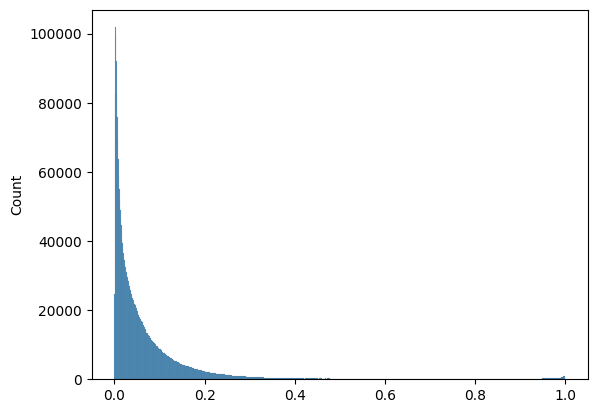

In [36]:
# import seaborn as sns
# st_data.layers['admix_probs'] = st_data.layers['admix_probs'].todense()
# nonzero_probs = s_data.layers['admix_probs'][st_data.layers['admix_probs'] > 0]

# sns.histplot(x=nonzero_probs)

import seaborn as sns
sc_data.layers['admix_probs'] = sc_data.layers['admix_probs'].todense()
nonzero_probs = sc_data.layers['admix_probs'][sc_data.layers['admix_probs'] > 0]

sns.histplot(x=nonzero_probs)

In [37]:
from admix_scores import estimate_correlation_preservation
cor_cors = estimate_correlation_preservation(st_data.X.T,sc_data.X.T)


ValueError: cm1 and cm2 must have the same number/order of genes (rows).

In [13]:
all(st_data.var_names.to_numpy() == sc_data.var_names.to_numpy())

ValueError: operands could not be broadcast together with shapes (924,) (957,) 

In [11]:
uncor_gene_ids = np.argwhere(cor_cors.values < 0.2).squeeze()
uncor_genes = st_data.var_names.to_numpy()[uncor_gene_ids]

len(uncor_genes)

42

In [38]:
import numpy as np
import pandas as pd
import importlib

import sc_score_from_st
import admix_scores
importlib.reload(sc_score_from_st)
importlib.reload(admix_scores)
from sc_score_from_st import get_scrna_admixture_scores_from_spatial_K


def make_clean_spatial_by_threshold(st_data, thr, probs_layer="admix_probs"):
    """Return a copy of st_data with X entries zeroed where admix_probs > thr."""
    st_clean = st_data.copy()
    probs = st_clean.layers[probs_layer]
    mask = probs > thr
    st_clean.X[mask] = 0.0
    return st_clean, mask


import numpy as np
from scipy import sparse

def threshold_for_removed_fraction(probs, X, target_removed_frac: float):
    """
    Choose thr so that removing entries with probs >= thr removes ~target_removed_frac
    of TOTAL transcript counts (sum of counts), considering only X>0 entries.

    Returns
    -------
    thr : float
    achieved : float  (fraction of transcript counts removed using probs >= thr)
    """
    r = float(target_removed_frac)
    r = min(max(r, 0.0), 1.0)
    if r == 0.0:
        return np.inf, 0.0
    if r == 1.0:
        return -np.inf, 1.0

    # Pull (pvals, counts) only where X>0
    if sparse.issparse(X):
        Xcoo = X.tocoo()
        counts = Xcoo.data.astype(float)
        pvals = np.asarray(probs[Xcoo.row, Xcoo.col]).ravel().astype(float)
    else:
        X = np.asarray(X)
        probs = np.asarray(probs)
        nz = X > 0
        counts = X[nz].astype(float)
        pvals = probs[nz].astype(float)

    good = np.isfinite(pvals) & np.isfinite(counts) & (counts > 0)
    pvals = pvals[good]
    counts = counts[good]
    if counts.size == 0:
        raise ValueError("No expressed transcripts found (X>0).")

    total = float(counts.sum())
    target = r * total

    # Sort by probability descending, accumulate transcript counts
    order = np.argsort(pvals)[::-1]
    p_sorted = pvals[order]
    c_sorted = counts[order]
    cum = np.cumsum(c_sorted)

    idx = int(np.searchsorted(cum, target, side="left"))
    idx = min(idx, len(p_sorted) - 1)
    thr = float(p_sorted[idx])

    # Achieved fraction if you remove probs >= thr (important!)
    removed = float(c_sorted[p_sorted >= thr].sum())
    achieved = removed / total

    return thr, achieved

# --- choose your target transcript-removal percentages here ---
target_removed_fracs = [0.0, 0.01, 0.02, 0.05, 0.10, 0.20]  # 0% to 20%

# pull probs once from the original st_data
probs = st_data.layers["admix_probs"]

all_dfs = []
gene_sets_by_setting = {}  # optional: keep gene_sets per threshold run

# always compute the baseline (unclean) once
base_df, base_gene_sets = get_scrna_admixture_scores_from_spatial_K(
    sc_data, st_data, cell_type_adj, adjust=False, return_gene_sets=True,
    min_expr_frac_specific=0.05,
    min_expr_frac_contam=0.05,
    signal_thres=0.4,
    max_prob_high=0.1,
    p_c=0.25,
    # exclude_genes=uncor_gene_ids.tolist(),
)
base_df["setting"] = "unclean"
base_df["removed_frac"] = 0.0
base_df["removed_pct"] = 0.0
base_df["threshold"] = np.nan
all_dfs.append(base_df)
gene_sets_by_setting["unclean"] = base_gene_sets

# now run for each removal fraction > 0
for r in target_removed_fracs:
    if r <= 0:
        continue

    thr, achieved = threshold_for_removed_fraction(probs, st_data.X, r)
    st_clean, mask = make_clean_spatial_by_threshold(st_data, thr, probs_layer="admix_probs")

    df, gs = get_scrna_admixture_scores_from_spatial_K(
        sc_data, st_clean, 
        cell_type_adj, adjust=False, 
        return_gene_sets=True,
        min_expr_frac_specific=0.05,
        min_expr_frac_contam=0.05,
        signal_thres=0.4,
        max_prob_high=0.1,
        p_c=0.25,
        # exclude_genes=uncor_gene_ids.tolist(),

    )

    df["setting"] = f"remove_{int(round(r*100))}pct"
    df["removed_frac_target"] = float(r)
    df["removed_frac"] = achieved
    df["removed_pct"] = achieved * 100.0
    df["threshold"] = thr

    all_dfs.append(df)
    gene_sets_by_setting[df["setting"].iloc[0]] = gs

score_df = pd.concat(all_dfs, axis=0, ignore_index=True)

score_df.head()

IndexError: too many indices for array: array is 0-dimensional, but 2 were indexed

In [39]:
## scRNA ref version:
import numpy as np
import pandas as pd
import importlib

import sc_score_from_st
import admix_scores
importlib.reload(sc_score_from_st)
importlib.reload(admix_scores)
from sc_score_from_st import get_scrna_admixture_scores_from_spatial_K


def make_corrected_from_admix_probs(
    adata,
    thr: float,
    probs_layer: str = "admix_probs",
    copy_layer_name: str = "X_corrected",
):
    """
    Return a copy of `adata` with X entries zeroed where admix_probs > thr.
    Also stores the corrected dense/sparse matrix in `.layers[copy_layer_name]`.
    """
    ad = adata.copy()
    probs = ad.layers[probs_layer]
    mask = np.asarray(probs) > thr
    ad.X[mask] = 0.0
    ad.layers[copy_layer_name] = ad.X.copy()  # optional snapshot
    return ad, mask

import numpy as np
from scipy import sparse

def threshold_for_removed_fraction(probs, X, target_removed_frac: float):
    """
    Choose thr so that removing entries with probs >= thr removes ~target_removed_frac
    of TOTAL transcript counts (sum of counts), considering only X>0 entries.

    Returns
    -------
    thr : float
    achieved : float  (fraction of transcript counts removed using probs >= thr)
    """
    r = float(target_removed_frac)
    r = min(max(r, 0.0), 1.0)
    if r == 0.0:
        return np.inf, 0.0
    if r == 1.0:
        return -np.inf, 1.0

    # Pull (pvals, counts) only where X>0
    if sparse.issparse(X):
        Xcoo = X.tocoo()
        counts = Xcoo.data.astype(float)
        pvals = np.asarray(probs[Xcoo.row, Xcoo.col]).ravel().astype(float)
    else:
        X = np.asarray(X)
        probs = np.asarray(probs)
        nz = X > 0
        counts = X[nz].astype(float)
        pvals = probs[nz].astype(float)

    good = np.isfinite(pvals) & np.isfinite(counts) & (counts > 0)
    pvals = pvals[good]
    counts = counts[good]
    if counts.size == 0:
        raise ValueError("No expressed transcripts found (X>0).")

    total = float(counts.sum())
    target = r * total

    # Sort by probability descending, accumulate transcript counts
    order = np.argsort(pvals)[::-1]
    p_sorted = pvals[order]
    c_sorted = counts[order]
    cum = np.cumsum(c_sorted)

    idx = int(np.searchsorted(cum, target, side="left"))
    idx = min(idx, len(p_sorted) - 1)
    thr = float(p_sorted[idx])

    # Achieved fraction if you remove probs >= thr (important!)
    removed = float(c_sorted[p_sorted >= thr].sum())
    achieved = removed / total

    return thr, achieved


def _prep_sc_for_scoring(sc_like, corrected_layer: str | None = None):
    """
    Helper: if corrected_layer is provided, pass it to scoring via `layer=...`.
    This assumes your `_get_counts_matrix_from_adata` supports pulling from layers by name.
    """
    return dict(layer=corrected_layer, use_raw=False)


# -------------------------
# SETTINGS YOU CONTROL
# -------------------------
target_removed_fracs = [0.01, 0.02, 0.05, 0.1]  # choose any grid
probs_layer = "admix_probs"

# sc_data: original scRNA reference (uncorrupted)
# sc_data_admixed: synthetically admixed scRNA (has .X + .layers['admixed'])
# sc_data_admixed.layers['admix_probs']: model probabilities on the admixed data
sc_data_admixed = sc_data.copy()  # <-- replace with your actual admixed data with probs in layers[probs_layer]
sc_data_admixed.X += sc_data_admixed.layers['admixed_counts']  # <-- if your admixed data is additive, add it to the original counts
#
# NOTE: you'll need to define sc_data_admixed in your notebook/environment.
# e.g. sc_data_admixed = sc_data.copy(); sc_data_admixed.layers['admixed']=...; sc_data_admixed.X = sc_data_admixed.layers['admixed']

# -------------------------
# RUN COMPARISON
# -------------------------
all_dfs = []
gene_sets_by_setting = {}  # optional

# 1) Baseline: original scRNA (sc_data) scored against *spatial* st_data
df_ref, gs_ref = get_scrna_admixture_scores_from_spatial_K(
    sc_data, sc_data, cell_type_adj,
    adjust=False,
    return_gene_sets=True,
    min_expr_frac_specific=0.05,
    min_expr_frac_contam=0.05,
    signal_thres=0.4,
    max_prob_high=0.1,
    p_c=0.25,
    #exclude_genes=uncor_gene_ids.tolist(),
)
df_ref["setting"] = "sc_reference"
df_ref["removed_frac_target"] = 0.0
df_ref["removed_frac"] = 0.0
df_ref["removed_pct"] = 0.0
df_ref["threshold"] = np.nan
all_dfs.append(df_ref)
gene_sets_by_setting["sc_reference"] = gs_ref

# 2) Synthetically admixed scRNA (use .layers['admixed'] as the counts matrix)
#    We score the *cells from sc_data_admixed* by passing `layer="admixed"`
df_syn, gs_syn = get_scrna_admixture_scores_from_spatial_K(
    sc_data, sc_data_admixed, cell_type_adj,
    adjust=False,
    return_gene_sets=True,
    #layer="admixed",          # <-- key change: use synthetic mixture counts
    use_raw=False,
    min_expr_frac_specific=0.05,
    min_expr_frac_contam=0.05,
    signal_thres=0.4,
    max_prob_high=0.1,
    p_c=0.25,
    # exclude_genes=uncor_gene_ids.tolist(),
)
df_syn["setting"] = "sc_synthetic_admixed"
df_syn["removed_frac_target"] = 0.0
df_syn["removed_frac"] = 0.0
df_syn["removed_pct"] = 0.0
df_syn["threshold"] = np.nan
all_dfs.append(df_syn)
gene_sets_by_setting["sc_synthetic_admixed"] = gs_syn

# 3) Corrected admixed scRNA: zero-out entries in sc_data_admixed where admix_probs > thr
probs = sc_data_admixed.layers[probs_layer]

for r in target_removed_fracs:
    if r <= 0:
        continue

    thr, achieved = threshold_for_removed_fraction(probs, sc_data_admixed.X, r)
    sc_corr, mask = make_corrected_from_admix_probs(
        sc_data_admixed, thr, probs_layer=probs_layer, copy_layer_name=f"X_corrected_{int(round(r*100))}pct"
    )

    print(achieved)

    df_corr, gs_corr = get_scrna_admixture_scores_from_spatial_K(
        sc_data, sc_corr, cell_type_adj,
        adjust=False,
        return_gene_sets=True,
        # IMPORTANT: corrected is now in sc_corr.X, so no layer needed
        min_expr_frac_specific=0.05,
        min_expr_frac_contam=0.05,
        signal_thres=0.4,
        max_prob_high=0.1,
        p_c=0.25,
        # exclude_genes=uncor_gene_ids.tolist(),
    )

    df_corr["setting"] = f"sc_admixed_corrected ({int(round(achieved*100))}%)"
    df_corr["removed_frac_target"] = float(r)
    df_corr["removed_frac"] = achieved
    df_corr["removed_pct"] = achieved * 100.0
    df_corr["threshold"] = float(thr)

    all_dfs.append(df_corr)
    gene_sets_by_setting[f"sc_admixed_corrected_remove_{int(round(r*100))}pct"] = gs_corr

score_df = pd.concat(all_dfs, axis=0, ignore_index=True)

# Optional: quick sanity summaries
summary = (
    score_df.groupby(["setting", "removed_pct", "cell_type"])["scores"]
    .agg(["mean", "median", "count"])
    .reset_index()
)
score_df.head(), summary.head()

0.010000684385019418
0.020000193063405117
0.050000080443085466
0.1000000371275779


(            cell cell_type    scores  dataset       setting  \
 0  p1t1-bcIFOQ-1    B-cell  0.083086  spatial  sc_reference   
 1  p1t1-bcATIE-1    B-cell  0.056726  spatial  sc_reference   
 2  p1t1-bcFVSC-1    B-cell  0.075117  spatial  sc_reference   
 3  p1t1-bcBZDW-1    B-cell  0.068299  spatial  sc_reference   
 4  p1t1-bcFSIA-1    B-cell  0.068709  spatial  sc_reference   
 
    removed_frac_target  removed_frac  removed_pct  threshold  
 0                  0.0           0.0          0.0        NaN  
 1                  0.0           0.0          0.0        NaN  
 2                  0.0           0.0          0.0        NaN  
 3                  0.0           0.0          0.0        NaN  
 4                  0.0           0.0          0.0        NaN  ,
                      setting  removed_pct cell_type      mean    median  count
 0  sc_admixed_corrected (1%)     1.000068    B-cell  0.077115  0.073472   5215
 1  sc_admixed_corrected (1%)     1.000068        DC  0.015992  0.012

In [40]:
score_df['removed_frac_target'].unique()

array([0.  , 0.01, 0.02, 0.05, 0.1 ])

In [41]:
for setting in list(gene_sets_by_setting.keys()):
    print(setting)
    gene_max = gene_sets_by_setting[setting]['prob_gene_per_type'].max(axis=0)
    for t in [0.01, 0.02, 0.05, 0.1]:
        print(f"  > {t}: {(gene_max > t).sum()}")

sc_reference
  > 0.01: 860
  > 0.02: 825
  > 0.05: 735
  > 0.1: 624
sc_synthetic_admixed
  > 0.01: 860
  > 0.02: 825
  > 0.05: 735
  > 0.1: 624
sc_admixed_corrected_remove_1pct
  > 0.01: 860
  > 0.02: 825
  > 0.05: 735
  > 0.1: 624
sc_admixed_corrected_remove_2pct
  > 0.01: 860
  > 0.02: 825
  > 0.05: 735
  > 0.1: 624
sc_admixed_corrected_remove_5pct
  > 0.01: 860
  > 0.02: 825
  > 0.05: 735
  > 0.1: 624
sc_admixed_corrected_remove_10pct
  > 0.01: 860
  > 0.02: 825
  > 0.05: 735
  > 0.1: 624


In [17]:
st_data.obs['cell_type'].value_counts()

cell_type
tumor          992
plasmablast    904
T CD4+         440
T CD8+         256
macrophage     248
neutrophil     208
B-cell         208
DC             144
fibroblast     144
Treg           144
monocyte        96
mast            56
NK              48
endothelial     32
epithelial      16
Name: count, dtype: int64

In [18]:
score_df.threshold.unique()

array([       nan, 0.65890205, 0.59676963, 0.49266899, 0.40257794,
       0.29307353])

In [19]:
from plotting import add_marker_set_scores, marker_set_dotplot
import plotting
importlib.reload(plotting)
st_clean, mask = make_clean_spatial_by_threshold(st_data, 0.05, probs_layer="admix_probs")
add_marker_set_scores(st_clean,gene_sets_by_setting['remove_1pct']['celltype_specific_genes'],score_prefix='ctspec',use_raw=False)


# The main plot axis is accessed via 'mainplot_ax' in the dictionary



# ax.set_title('NSCLC ST Sample 1: Cell Type Specific Gene Scores (Unclean Data)')

/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:

Text(0.5, 1.0, 'NSCLC ST Sample 1: Cell Type Specific Gene Scores (1pct cleaning)')

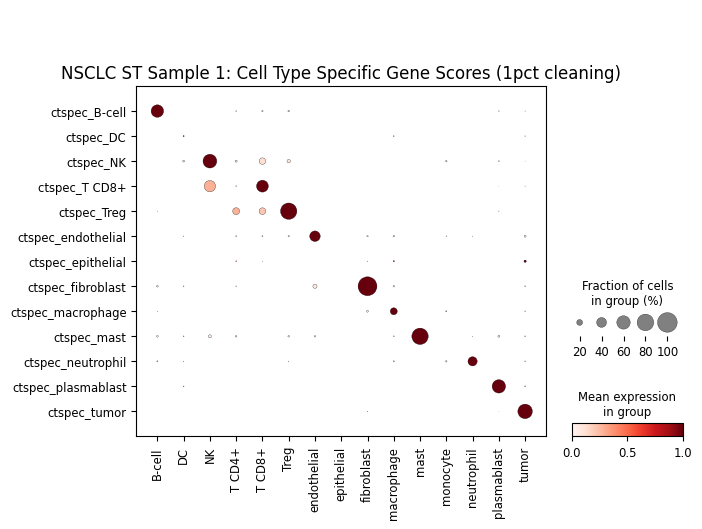

In [20]:
importlib.reload(plotting)
import matplotlib.pyplot as plt
# fig,ax = plt.subplots(figsize=(8,12),dpi=150)
dp = marker_set_dotplot(st_clean,cell_type_key='cell_type',score_prefix='ctspec')
ax_dict = dp.get_axes()
ax = ax_dict['mainplot_ax']


ax.set_title('NSCLC ST Sample 1: Cell Type Specific Gene Scores (1pct cleaning)')

In [ ]:
# clean_gene_sets.keys()

In [ ]:
# import pickle
# pickle.dump(unclean_gene_sets, open('/home/jwinchel/Syndri/nsclc_playground/unclean_gene_sets.pickle', 'wb'))
# pickle.dump(clean_gene_sets, open('/home/jwinchel/Syndri/nsclc_playground/clean_gene_sets.pickle', 'wb'))

Text(0.5, 1.0, 'Cell Type Adjacency Matrix')

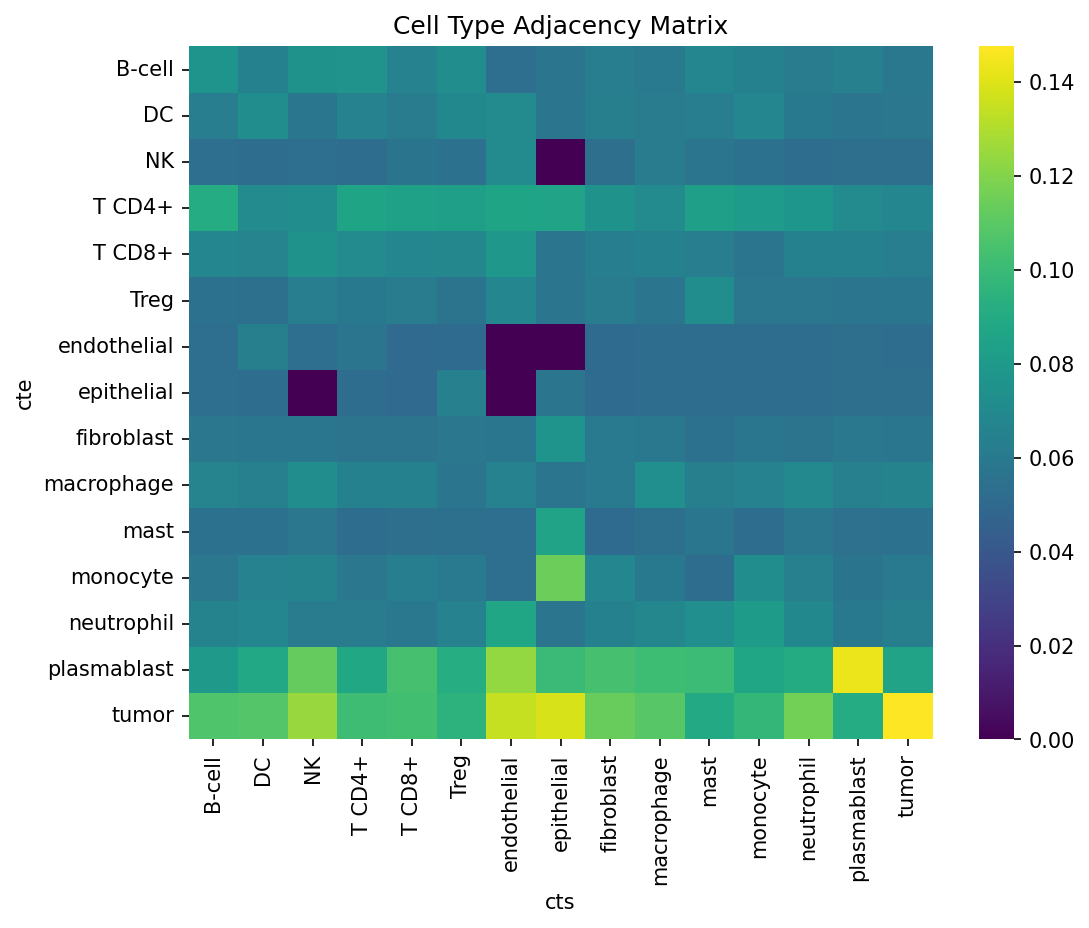

In [21]:
import seaborn as sns
K_norm = cell_type_adj.divide(cell_type_adj.sum(axis=0), axis=1)
fig, ax= plt.subplots(figsize=(8,6),dpi=150)
ax = sns.heatmap(K_norm,cmap='viridis')
# ax= sns.heatmap(cell_type_adj,cmap='viridis')
ax.set_title('Cell Type Adjacency Matrix')


In [42]:
score_df[['setting','threshold','removed_frac_target','removed_frac','removed_pct']].drop_duplicates()

,setting,threshold,removed_frac_target,removed_frac,removed_pct
0,sc_reference,NaN,0.00,0.000000,0.000000
39870,sc_synthetic_admixed,NaN,0.00,0.000000,0.000000
79740,sc_admixed_corrected (1%),0.988719,0.01,0.010001,1.000068
119610,sc_admixed_corrected (2%),0.953506,0.02,0.020000,2.000019
159480,sc_admixed_corrected (5%),0.480089,0.05,0.050000,5.000008
199350,sc_admixed_corrected (10%),0.286866,0.10,0.100000,10.000004


In [48]:
ct_order = score_df[score_df['setting']=='sc_synthetic_admixed'].groupby('cell_type')['scores'].median().reset_index().sort_values('scores',ascending=False)['cell_type'].tolist()

In [44]:
score_df

,cell,cell_type,scores,dataset,setting,removed_frac_target,removed_frac,removed_pct,threshold
0,p1t1-bcIFOQ-1,B-cell,0.083086,spatial,sc_reference,0.0,0.0,0.000000,NaN
1,p1t1-bcATIE-1,B-cell,0.056726,spatial,sc_reference,0.0,0.0,0.000000,NaN
2,p1t1-bcFVSC-1,B-cell,0.075117,spatial,sc_reference,0.0,0.0,0.000000,NaN
3,p1t1-bcBZDW-1,B-cell,0.068299,spatial,sc_reference,0.0,0.0,0.000000,NaN
4,p1t1-bcFSIA-1,B-cell,0.068709,spatial,sc_reference,0.0,0.0,0.000000,NaN
...,...,...,...,...,...,...,...,...,...
239215,p7t2-bcDFNQ-1,tumor,0.000000,spatial,sc_admixed_corrected (10%),0.1,0.1,10.000004,0.286866
239216,p7t2-bcAHMK-1,tumor,0.008821,spatial,sc_admixed_corrected (10%),0.1,0.1,10.000004,0.286866
239217,p7t2-bcFTQS-1,tumor,0.017058,spatial,sc_admixed_corrected (10%),0.1,0.1,10.000004,0.286866
239218,p7t2-bcHEFU-1,tumor,0.000000,spatial,sc_admixed_corrected (10%),0.1,0.1,10.000004,0.286866


In [49]:
ct_order

['plasmablast',
 'neutrophil',
 'B-cell',
 'T CD8+',
 'T CD4+',
 'NK',
 'Treg',
 'mast',
 'fibroblast',
 'endothelial',
 'epithelial',
 'tumor',
 'monocyte',
 'DC',
 'macrophage']

/tmp/ipykernel_4065631/3722568063.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ = ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


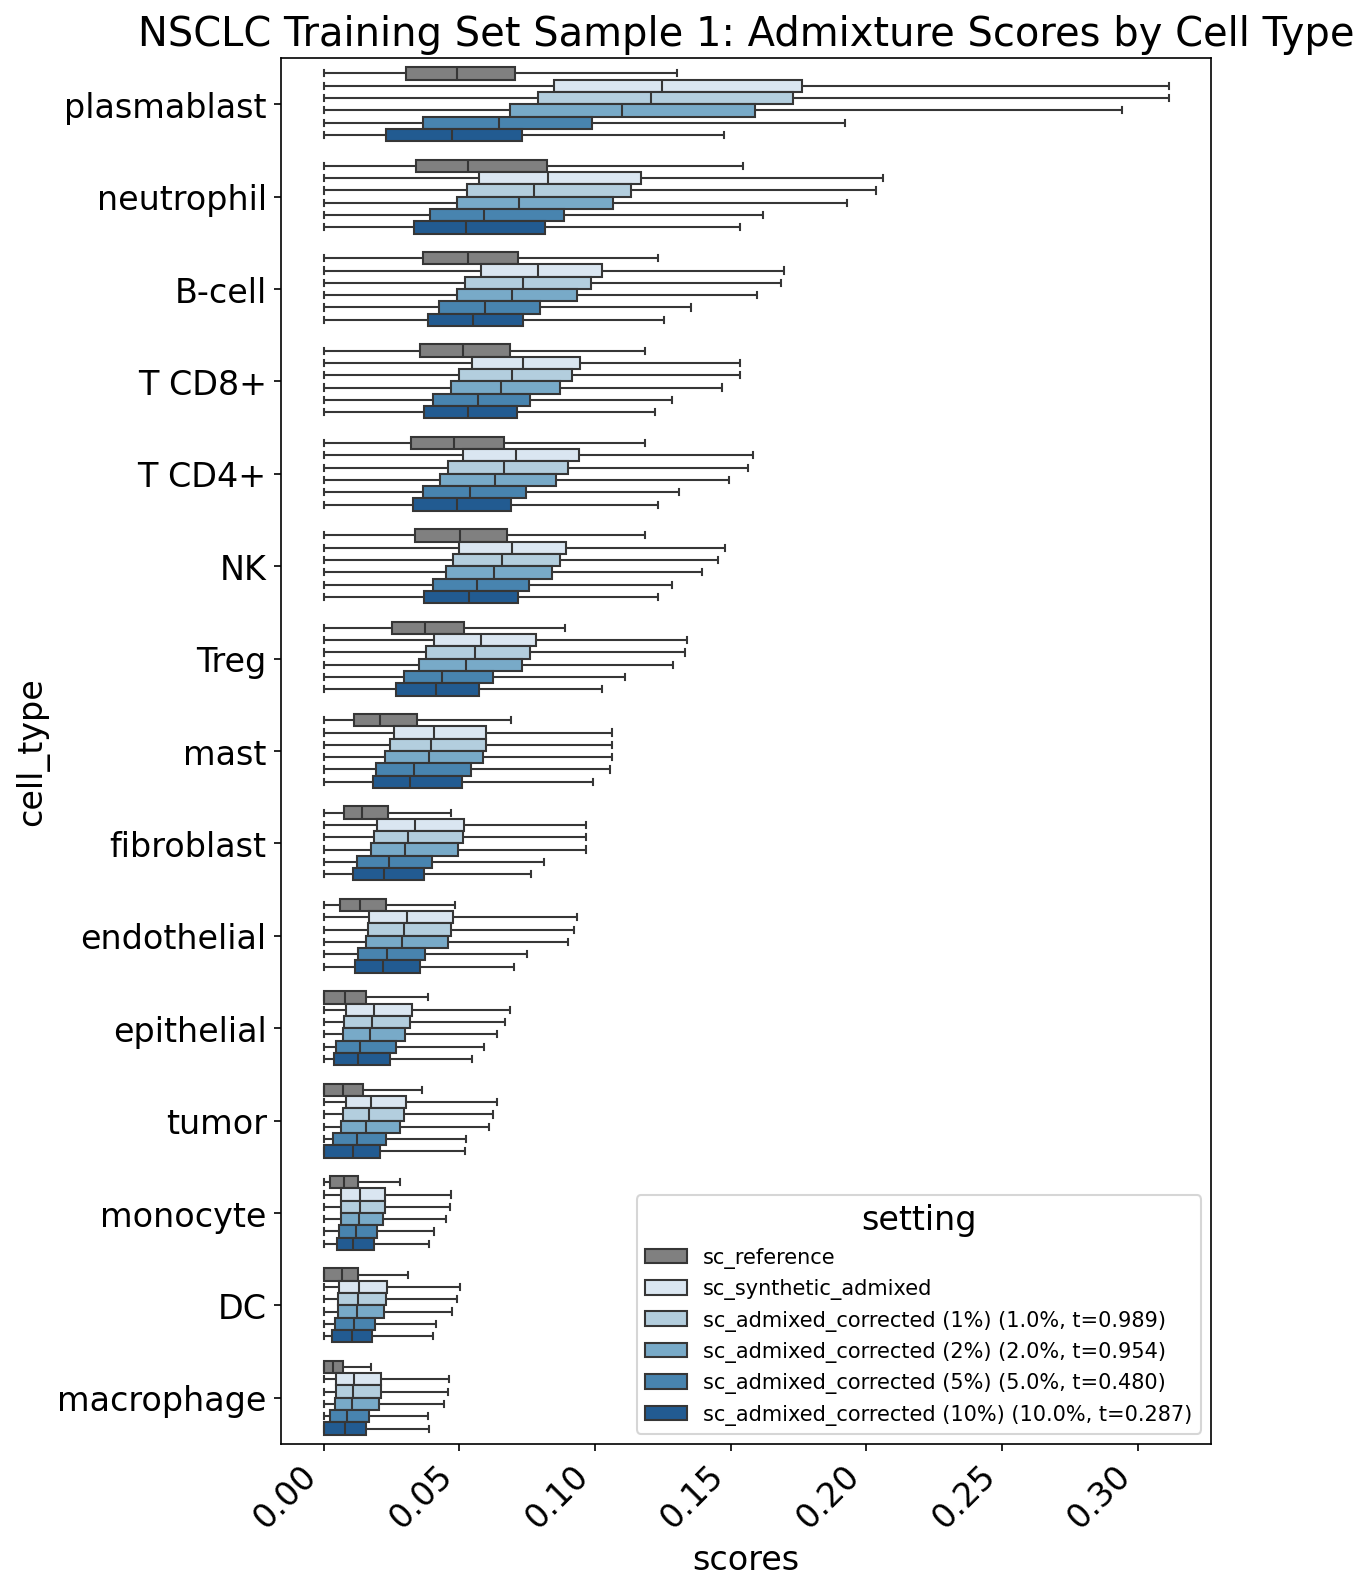

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt
# sns.heatmap(cell_type_adj)
palette = ["gray"] + sns.color_palette("Blues", n_colors=len(score_df['setting'].unique())-1)
fig,ax = plt.subplots(figsize=(8,12),dpi=150)
# plt.rcParams.update({'font.size': 16})
# sns.boxplot(data=score_df[score_df['setting'].isin(['unclean','remove_1pct'])],x='scores',y='cell_type',hue='setting',ax=ax,order=ct_order,showfliers=False,palette=palette)
sns.boxplot(data=score_df,x='scores',y='cell_type',hue='setting',ax=ax,order=ct_order,showfliers=False,palette=palette)

ax.set_title('NSCLC Training Set Sample 1: Admixture Scores by Cell Type')
# ax.xlim([0,0.4])
_ = ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
removed_map = (
    score_df
    .drop_duplicates("setting")
    .set_index("setting")[["removed_pct", "threshold"]]
    .to_dict("index")
)
handles, labels = ax.get_legend_handles_labels()
new_labels = []
for label in labels:
    info = removed_map.get(label, None)
    if info and not np.isnan(info["threshold"]):
        new_labels.append(
            f"{label} ({info['removed_pct']:.1f}%, t={info['threshold']:.3f})"
        )
    else:
        new_labels.append(label)
        
ax.legend(handles, new_labels, title="setting",fontsize=10)

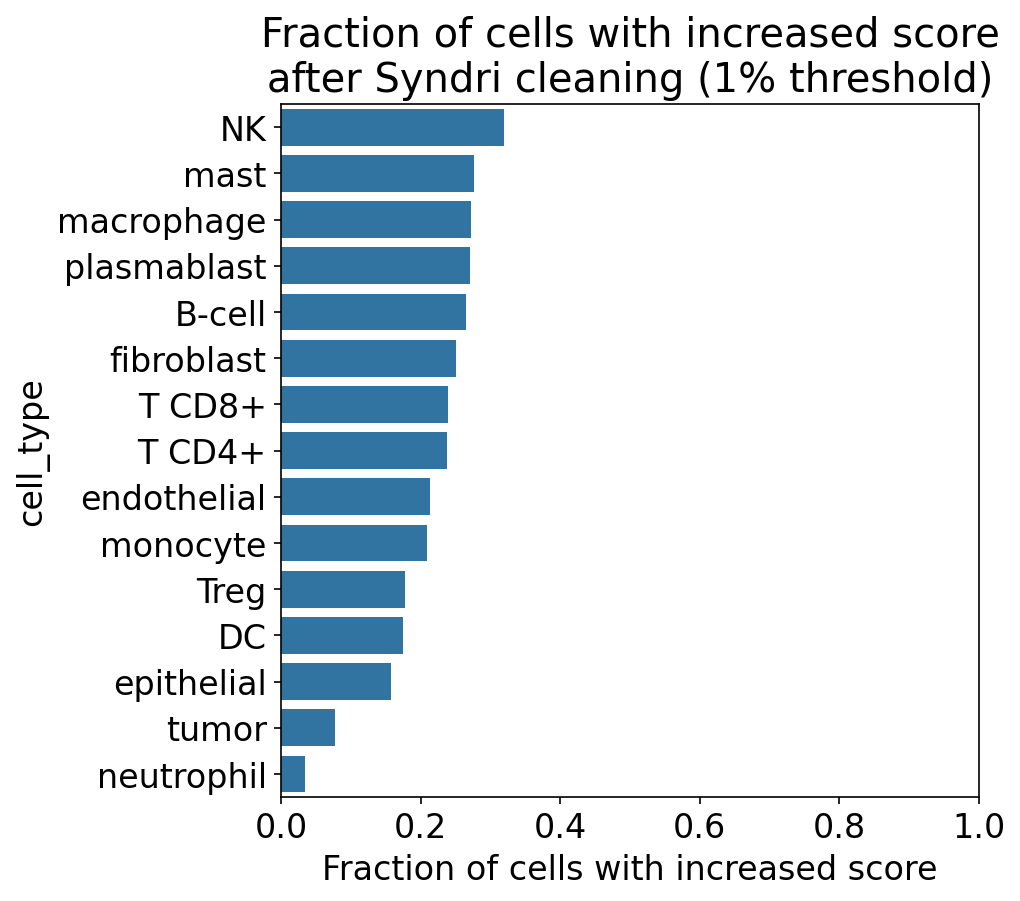

In [24]:
score_df['cell'] = score_df['cell'].astype(str)
baseline = "unclean"
comparison = "remove_1pct"   # or loop over settings

df_pivot = (
    score_df.drop(columns=['threshold','removed_frac_target'])[score_df["setting"].isin([baseline, comparison])]
    .pivot_table(index=["cell", "cell_type"],
                 columns="setting",
                 values="scores")
    
)
df_pivot.isna().sum()

df_pivot["delta"] = df_pivot[comparison] - df_pivot[baseline]
df_pivot["went_up"] = df_pivot["delta"] > 0

df_pivot

frac_up = (
    df_pivot.groupby("cell_type")["went_up"]
            .mean()
            .sort_values(ascending=False)
)

frac_up

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6),dpi=150)
sns.barplot(x=frac_up.values, y=frac_up.index)
plt.xlabel("Fraction of cells with increased score")
plt.xlim(0,1)
plt.title('Fraction of cells with increased score\nafter Syndri cleaning (1% threshold)')
plt.show()

In [25]:
import numpy as np
import pandas as pd
from scipy import sparse

def transcripts_removed_by_cell_type(
    st_data,
    *,
    prob_layer="admix_probs",
    threshold=0.25,
    cell_type_key="cell_type",
    counts_layer=None,     # None => use st_data.X; else st_data.layers[counts_layer]
    include_zeros=False,   # if False, only considers genes with count>0
    return_per_cell=True,
):
    """
    Uses:
      counts: st_data.X (or counts_layer)
      probs:  st_data.layers[prob_layer]
    Computes per cell:
      total_tx = sum(counts)
      removed_tx = sum(counts where prob > threshold)
      frac_removed = removed_tx / total_tx
    Aggregates per cell type.

    Works with dense or sparse counts and dense probs.
    """

    if cell_type_key not in st_data.obs.columns:
        raise KeyError(f"{cell_type_key!r} not in st_data.obs")

    # --- counts matrix (cells x genes) ---
    counts = st_data.layers[counts_layer] if counts_layer is not None else st_data.X
    probs = st_data.layers[prob_layer]

    # Ensure arrays
    is_counts_sparse = sparse.issparse(counts)
    probs = np.asarray(probs)  # probs generally dense; this is fine

    n_cells, n_genes = st_data.shape
    if probs.shape != (n_cells, n_genes):
        raise ValueError(f"probs shape {probs.shape} != st_data.shape {st_data.shape}")

    # total transcripts per cell
    if is_counts_sparse:
        total_tx = np.asarray(counts.sum(axis=1)).ravel()
    else:
        counts = np.asarray(counts)
        total_tx = counts.sum(axis=1)

    total_tx = total_tx.astype(float)
    total_tx_safe = np.where(total_tx == 0, 1.0, total_tx)

    # removed transcripts per cell:
    # sum counts where probs > threshold
    if is_counts_sparse:
        removed_tx = np.zeros(n_cells, dtype=float)
        counts_csr = counts.tocsr()
        for i in range(n_cells):
            start, end = counts_csr.indptr[i], counts_csr.indptr[i+1]
            idx = counts_csr.indices[start:end]
            data = counts_csr.data[start:end].astype(float)

            if idx.size == 0:
                continue

            p = probs[i, idx]
            if include_zeros:
                # include_zeros doesn't matter for sparse since only nonzeros are stored
                pass

            removed_tx[i] = data[p > threshold].sum()
    else:
        # dense: optionally ignore zeros
        if include_zeros:
            removed_tx = (counts * (probs > threshold)).sum(axis=1).astype(float)
        else:
            mask_nz = counts > 0
            removed_tx = (counts * (probs > threshold) * mask_nz).sum(axis=1).astype(float)

    frac_removed = removed_tx / total_tx_safe

    per_cell = pd.DataFrame({
        "cell": st_data.obs_names.astype(str),
        "cell_type": st_data.obs[cell_type_key].astype(str).values,
        "total_tx": total_tx,
        "removed_tx": removed_tx,
        "frac_removed": frac_removed,
        "threshold": float(threshold),
    })

    summary = (
        per_cell.groupby("cell_type")
        .agg(
            n_cells=("cell", "size"),
            mean_total_tx=("total_tx", "mean"),
            mean_removed_tx=("removed_tx", "mean"),
            mean_frac_removed=("frac_removed", "mean"),
            median_frac_removed=("frac_removed", "median"),
        )
        .sort_values("mean_frac_removed", ascending=False)
        .reset_index()
    )
    summary["threshold"] = float(threshold)

    if return_per_cell:
        return summary, per_cell
    return summary

In [26]:
summary, per_cell = transcripts_removed_by_cell_type(
    st_data,
    threshold=0.736,
    prob_layer="admix_probs",
    cell_type_key="cell_type",
    counts_layer=None,   # use st_data.X
    return_per_cell=True,
)

per_cell



,cell,cell_type,total_tx,removed_tx,frac_removed,threshold
0,156889,DC,23.0,0.0,0.000000,0.736
1,156890,endothelial,26.0,0.0,0.000000,0.736
2,156891,endothelial,74.0,3.0,0.040541,0.736
3,156892,DC,60.0,2.0,0.033333,0.736
4,156893,macrophage,52.0,3.0,0.057692,0.736
...,...,...,...,...,...,...
97997,257199,DC,47.0,3.0,0.063830,0.736
97998,257200,fibroblast,95.0,1.0,0.010526,0.736
97999,257201,DC,82.0,0.0,0.000000,0.736
98000,257202,B-cell,24.0,4.0,0.166667,0.736


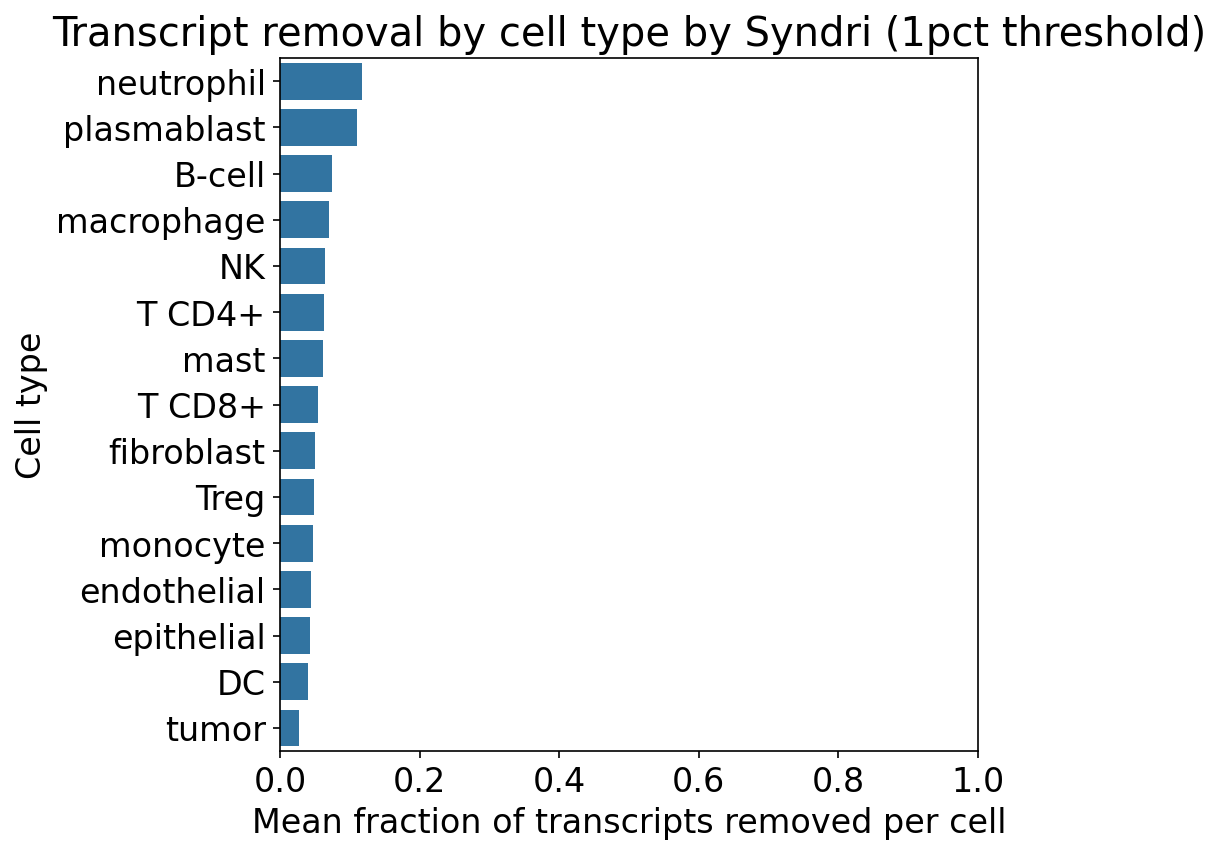

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6),dpi=150)
sns.barplot(data=summary, x="mean_frac_removed", y="cell_type")
plt.xlim(0, 1)
plt.xlabel("Mean fraction of transcripts removed per cell")
plt.ylabel("Cell type")
plt.title(f"Transcript removal by cell type by Syndri (1pct threshold)")
plt.show()

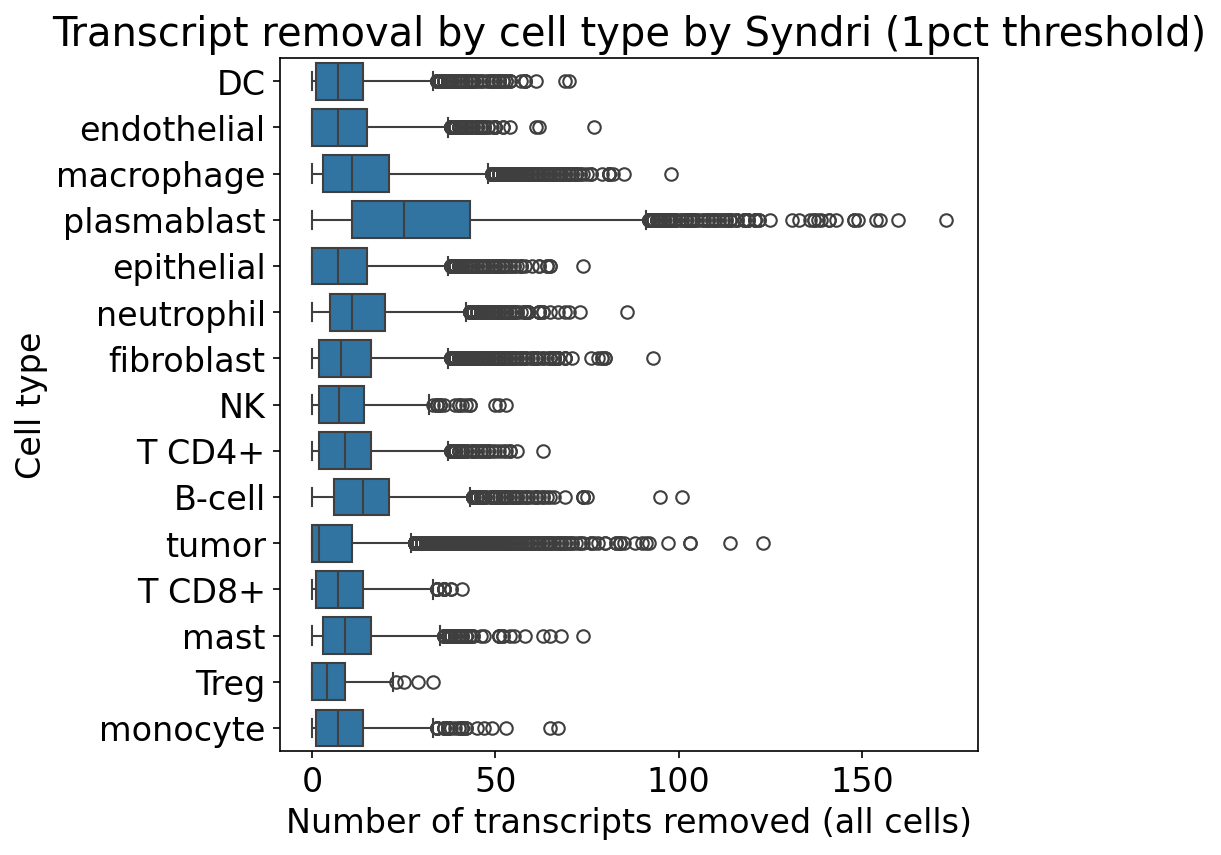

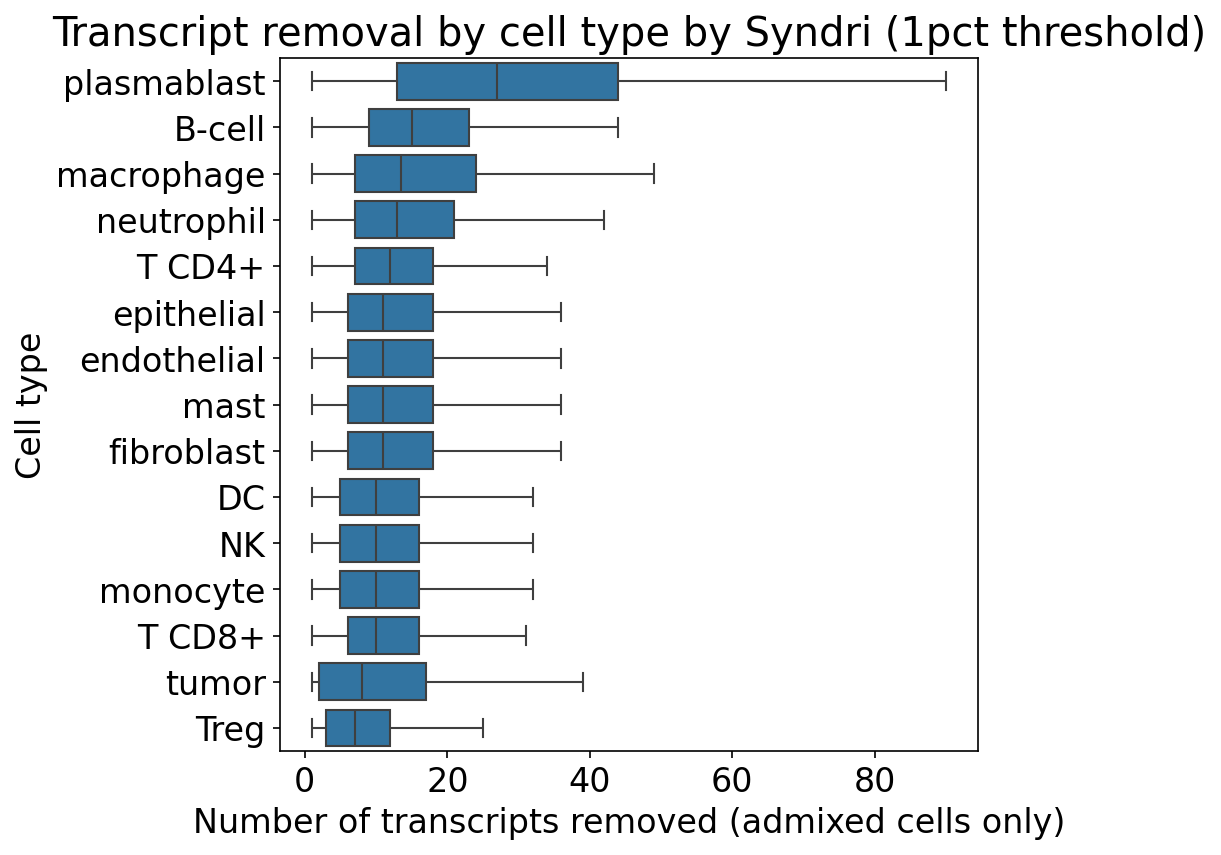

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

ct_order = per_cell.groupby('cell_type')['removed_tx'].median().sort_values(ascending=False).index.tolist()
plt.figure(figsize=(6,6),dpi=150)
sns.boxplot(data=per_cell, x="removed_tx", y="cell_type")#,order=ct_order,showfliers=False)
# plt.xlim(0, 1)
plt.xlabel("Number of transcripts removed (all cells)")
plt.ylabel("Cell type")
plt.title(f"Transcript removal by cell type by Syndri (1pct threshold)")
plt.show()

ct_order = per_cell[per_cell['removed_tx'] > 0].groupby('cell_type')['removed_tx'].median().sort_values(ascending=False).index.tolist()
plt.figure(figsize=(6,6),dpi=150)
sns.boxplot(data=per_cell[per_cell['removed_tx'] > 0], x="removed_tx", y="cell_type",order=ct_order,showfliers=False)
# plt.xlim(0, 1)
plt.xlabel("Number of transcripts removed (admixed cells only)")
plt.ylabel("Cell type")
plt.title(f"Transcript removal by cell type by Syndri (1pct threshold)")
plt.show()
